# 02b · Compare slides from five hospitals

The first example showed that one slide could be read and annotated on the Mac. I now want to check the same workflow on two slides from each hospital.

The questions are practical: do all ten files open, what are the physical pixel sizes, and do their image pyramids differ? 
The answers will help us choose how to read tiles in the next step.
This notebook covers image inspection; no model has been trained.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import json
import platform
import sys
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Patch
import numpy as np
import openslide
import pandas as pd
from PIL import ImageCms
from IPython.display import display

ROOT = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "src" / "fetch_camelyon17_sample.py").is_file()
)
sys.path.insert(0, str(ROOT / "src"))
from fetch_camelyon17_sample import (
    INSPECTION_MANIFEST, load_inspection_manifest, fetch_inspection_set,
)

OUT = ROOT / "data" / "derived" / "camelyon17" / "hospital_comparison"
(OUT / "thumbnails").mkdir(parents=True, exist_ok=True)


## 1. Choose a small, reproducible sample

Each hospital contributes one negative slide and one macrometastasis slide with an XML annotation. Keeping the same label categories makes the examples easier to compare. The annotated slides also let us check whether outlines use the image coordinates correctly.

Within each hospital and category, I chose the smallest TIFF. This keeps the ten TIFFs at about 16.76 GB and includes the hospital 4 slide we already inspected. File size can depend on tissue content and compression, so these examples do not establish typical hospital appearance or the frequency of any label.

The fixed selection is in `manifests/inspection_slides.csv`. It records the IDs, labels, hospital codes, source locations, sizes, and MD5 hashes. Saving the selection makes it clear which files produced the results.


In [2]:
records = load_inspection_manifest()
selection = pd.DataFrame(records)
selection["hospital"] = selection["hospital"].astype(int)
selection["stored_GB"] = selection["image_bytes"].astype("int64") / 1e9
selection["has_XML"] = selection["annotation_key"].ne("")
display(selection[["hospital", "label", "slide_id", "stored_GB", "has_XML"]].round(3))
print(f"Total TIFF storage: {selection['stored_GB'].sum():.2f} GB")
manifest_sha256 = hashlib.sha256(INSPECTION_MANIFEST.read_bytes()).hexdigest()


,hospital,label,slide_id,stored_GB,has_XML
0,0,negative,patient_019_node_4.tif,1.258,False
1,0,macro,patient_012_node_0.tif,1.974,True
2,1,negative,patient_031_node_4.tif,1.790,False
3,1,macro,patient_034_node_3.tif,3.947,True
4,2,negative,patient_053_node_4.tif,0.610,False
5,2,macro,patient_044_node_4.tif,1.323,True
6,3,negative,patient_065_node_2.tif,1.452,False
7,3,macro,patient_075_node_4.tif,3.228,True
8,4,negative,patient_083_node_4.tif,0.306,False
9,4,macro,patient_092_node_1.tif,0.875,True


Total TIFF storage: 16.76 GB


## 2. Download and verify the selected files

The downloader checks each manifest row against the saved metadata before downloading that slide. It then checks the file size and published MD5. These checks help distinguish a damaged download from a problem with the image reader.

> Existing files are verified and reused. Up to three files download at once, and completed files remain available if a later download fails. An incomplete file starts over on the next run. The downloader checks available disk space before starting the set.


In [3]:
samples = fetch_inspection_set()
if [sample["slide_id"] for sample in samples] != selection["slide_id"].tolist():
    raise ValueError("Downloaded sample order differs from the fixed manifest.")
print(f"Verified {len(samples)} TIFFs and "
      f"{sum('annotation' in sample['files'] for sample in samples)} XML files.")


Using the verified local metadata snapshot.
Inspection set: 10 slides; 0.00 GB to download.
[1/10] Hospital 0, negative: patient_019_node_4.tif
[2/10] Hospital 0, macro: patient_012_node_0.tif
[3/10] Hospital 1, negative: patient_031_node_4.tif
Using the verified local metadata snapshot.
Using the verified local metadata snapshot.
Using the verified local metadata snapshot.
Verified local patient_012_node_0.xml.
Verified local patient_019_node_4.tif.
[4/10] Hospital 1, macro: patient_034_node_3.tif
Using the verified local metadata snapshot.
Verified local patient_034_node_3.xml.
Verified local patient_031_node_4.tif.
[5/10] Hospital 2, negative: patient_053_node_4.tif
Using the verified local metadata snapshot.
Verified local patient_012_node_0.tif.
[6/10] Hospital 2, macro: patient_044_node_4.tif
Using the verified local metadata snapshot.
Verified local patient_044_node_4.xml.
Verified local patient_053_node_4.tif.
[7/10] Hospital 3, negative: patient_065_node_2.tif
Using the verifi

## 3. Read the metadata and make thumbnails

For each image, record the full dimensions, number of resolution levels, physical pixel sizes, and any objective magnification. Missing metadata stays missing. The detected file format is also recorded; a value such as `generic-tiff` does not identify a particular scanner.

The physical pixel size tells us how much tissue distance a pixel covers. It is needed when we choose a consistent tile scale across images. The level number alone does not tell us that scale.

Each thumbnail has a maximum width or height of 1,000 pixels. If an embedded color profile is available, the code converts it to sRGB. Otherwise it displays the stored RGB values. These small images let us inspect all hospitals without decoding the full-resolution slides into memory.


In [4]:
def optional_mpp(properties, key):
    value = properties.get(key)
    if value is None:
        return None
    number = float(value)
    if not np.isfinite(number) or number <= 0:
        raise ValueError(f"Invalid physical pixel size: {key}={value}")
    return number


metadata_rows, level_rows, thumbnails = [], [], {}
for sample in samples:
    slide_id = sample["slide_id"]
    with openslide.OpenSlide(sample["files"]["image"]["path"]) as slide:
        width, height = slide.dimensions
        properties = dict(slide.properties)
        mpp_x = optional_mpp(properties, openslide.PROPERTY_NAME_MPP_X)
        mpp_y = optional_mpp(properties, openslide.PROPERTY_NAME_MPP_Y)
        metadata_rows.append({
            "slide_id": slide_id, "hospital": sample["hospital"], "label": sample["label"],
            "width_px": width, "height_px": height, "gigapixels": width * height / 1e9,
            "level_count": slide.level_count, "mpp_x": mpp_x, "mpp_y": mpp_y,
            "objective_magnification": properties.get(openslide.PROPERTY_NAME_OBJECTIVE_POWER),
            "format": properties.get(openslide.PROPERTY_NAME_VENDOR),
            "has_color_profile": slide.color_profile is not None,
            "has_XML": "annotation" in sample["files"],
        })
        for level, (level_width, level_height) in enumerate(slide.level_dimensions):
            downsample = slide.level_downsamples[level]
            level_rows.append({
                "slide_id": slide_id, "hospital": sample["hospital"], "level": level,
                "width_px": level_width, "height_px": level_height, "downsample": downsample,
                "approx_mpp_x": mpp_x * downsample if mpp_x is not None else None,
                "approx_mpp_y": mpp_y * downsample if mpp_y is not None else None,
            })
        thumbnail = slide.get_thumbnail((1000, 1000))
        if slide.color_profile is not None:
            thumbnail = ImageCms.profileToProfile(
                thumbnail, slide.color_profile, ImageCms.createProfile("sRGB"),
                renderingIntent=ImageCms.getDefaultIntent(slide.color_profile),
                outputMode="RGB",
            )
        thumbnails[slide_id] = thumbnail
        thumbnail.save(OUT / "thumbnails" / f"{Path(slide_id).stem}.png",
                       icc_profile=thumbnail.info.get("icc_profile"))

metadata = pd.DataFrame(metadata_rows)
level_table = pd.DataFrame(level_rows)
display(metadata[["hospital", "label", "slide_id", "width_px", "height_px",
                  "level_count", "mpp_x", "mpp_y", "objective_magnification", "format"]]
        .round(6).fillna("not recorded"))


,hospital,label,slide_id,width_px,height_px,level_count,mpp_x,mpp_y,objective_magnification,format
0,0,negative,patient_019_node_4.tif,96651,197226,9,0.243094,0.243094,not recorded,generic-tiff
1,0,macro,patient_012_node_0.tif,96651,197226,9,0.243094,0.243094,not recorded,generic-tiff
2,1,negative,patient_031_node_4.tif,94968,210579,9,0.243094,0.243094,not recorded,generic-tiff
3,1,macro,patient_034_node_3.tif,94968,210579,9,0.243094,0.243094,not recorded,generic-tiff
4,2,negative,patient_053_node_4.tif,57344,39424,8,0.226316,0.226321,not recorded,generic-tiff
5,2,macro,patient_044_node_4.tif,57344,86016,8,0.226316,0.226321,not recorded,generic-tiff
6,3,negative,patient_065_node_2.tif,94968,210579,9,0.243094,0.243094,not recorded,generic-tiff
7,3,macro,patient_075_node_4.tif,96651,197226,9,0.243094,0.243094,not recorded,generic-tiff
8,4,negative,patient_083_node_4.tif,160256,44032,10,0.250000,0.250000,not recorded,philips
9,4,macro,patient_092_node_1.tif,184320,93696,10,0.250000,0.250000,not recorded,philips


## 4. Inspect a resolution pyramid

This table shows every level for one selected file. Change `slide_to_inspect` to another filename from the selection to inspect its pyramid. The complete table for all ten files is saved at the end.

The approximate pixel size at a level is the full-resolution pixel size multiplied by OpenSlide's downsample factor. Factors can differ slightly from whole numbers because level dimensions are rounded. Comparing these values helps explain why choosing the same level number everywhere may produce different physical scales.


In [5]:
slide_to_inspect = selection.iloc[0]["slide_id"]
display(level_table.loc[level_table["slide_id"].eq(slide_to_inspect),
                        ["level", "width_px", "height_px", "downsample",
                         "approx_mpp_x", "approx_mpp_y"]].round(6))


,level,width_px,height_px,downsample,approx_mpp_x,approx_mpp_y
0,0,96651,197226,1.000000,0.243094,0.243094
1,1,48325,98613,2.000010,0.486190,0.486190
2,2,24162,49306,4.000082,0.972395,0.972395
3,3,12081,24653,8.000165,1.944791,1.944791
4,4,6040,12326,16.001316,3.889821,3.889821
5,5,3020,6163,32.002632,7.779642,7.779642
6,6,1510,3081,64.010458,15.560547,15.560547
7,7,755,1540,128.041700,31.126146,31.126146
8,8,377,770,256.253181,62.293564,62.293564


## 5. Check the annotation coordinates

A slide label tells us the category of the whole image. The XML outlines tell us where the supplied tumor regions are. Checking the outlines now can reveal a coordinate mistake before we start extracting tiles.

The parser uses the same full-resolution coordinate convention as the first notebook. It keeps tumor and exclusion outlines separate and checks that every coordinate lies inside the image. For the selected negative slides, no XML is supplied; their annotation counts are left blank.


In [6]:
def read_polygons(path, width, height):
    root = ET.parse(path).getroot()
    if root.tag != "ASAP_Annotations":
        raise ValueError("Expected an ASAP annotation file.")
    polygons = []
    for annotation in root.findall("./Annotations/Annotation"):
        group = annotation.get("PartOfGroup")
        if annotation.get("Type") != "Polygon" or group not in {"Tumor", "Exclusion"}:
            raise ValueError("Inspect the unfamiliar annotation type or group.")
        points = sorted(annotation.findall("./Coordinates/Coordinate"),
                        key=lambda point: int(point.attrib["Order"]))
        xy = np.array([(float(p.attrib["X"]), float(p.attrib["Y"])) for p in points])
        if len(xy) < 3 or not np.isfinite(xy).all():
            raise ValueError("A polygon has too few points or invalid coordinates.")
        if (xy < 0).any() or (xy[:, 0] > width).any() or (xy[:, 1] > height).any():
            raise ValueError("Annotation coordinates fall outside the image.")
        polygons.append({"group": group, "xy": xy})
    if not any(polygon["group"] == "Tumor" for polygon in polygons):
        raise ValueError("The selected macro slide has no tumor polygon.")
    return polygons


annotations, annotation_rows = {}, []
metadata_by_id = {row["slide_id"]: row for row in metadata_rows}
for sample in samples:
    slide_id = sample["slide_id"]
    info = metadata_by_id[slide_id]
    has_xml = "annotation" in sample["files"]
    polygons = read_polygons(sample["files"]["annotation"]["path"],
                             info["width_px"], info["height_px"]) if has_xml else []
    annotations[slide_id] = polygons
    annotation_rows.append({
        "slide_id": slide_id, "hospital": sample["hospital"], "has_XML": has_xml,
        "tumor_polygons": sum(p["group"] == "Tumor" for p in polygons) if has_xml else None,
        "exclusion_polygons": sum(p["group"] == "Exclusion" for p in polygons) if has_xml else None,
    })
annotation_table = pd.DataFrame(annotation_rows)
display(annotation_table.fillna("not supplied"))


,slide_id,hospital,has_XML,tumor_polygons,exclusion_polygons
0,patient_019_node_4.tif,0,False,not supplied,not supplied
1,patient_012_node_0.tif,0,True,2.0,0.0
2,patient_031_node_4.tif,1,False,not supplied,not supplied
3,patient_034_node_3.tif,1,True,54.0,0.0
4,patient_053_node_4.tif,2,False,not supplied,not supplied
5,patient_044_node_4.tif,2,True,5.0,0.0
6,patient_065_node_2.tif,3,False,not supplied,not supplied
7,patient_075_node_4.tif,3,True,34.0,0.0
8,patient_083_node_4.tif,4,False,not supplied,not supplied
9,patient_092_node_1.tif,4,True,4.0,0.0


## 6. View all five hospitals

Each row shows one hospital, with a negative example on the left and an annotated macro example on the right. The colored lines come from the published XML files.

> Every whole slide is fitted into its panel, so the images are not displayed at a common physical scale. 

> The grid is useful for spotting unreadable files, unusual backgrounds, and obvious outline-placement problems. 

> Color differences can also reflect tissue content and slide preparation, so these two examples per hospital cannot isolate a hospital effect.


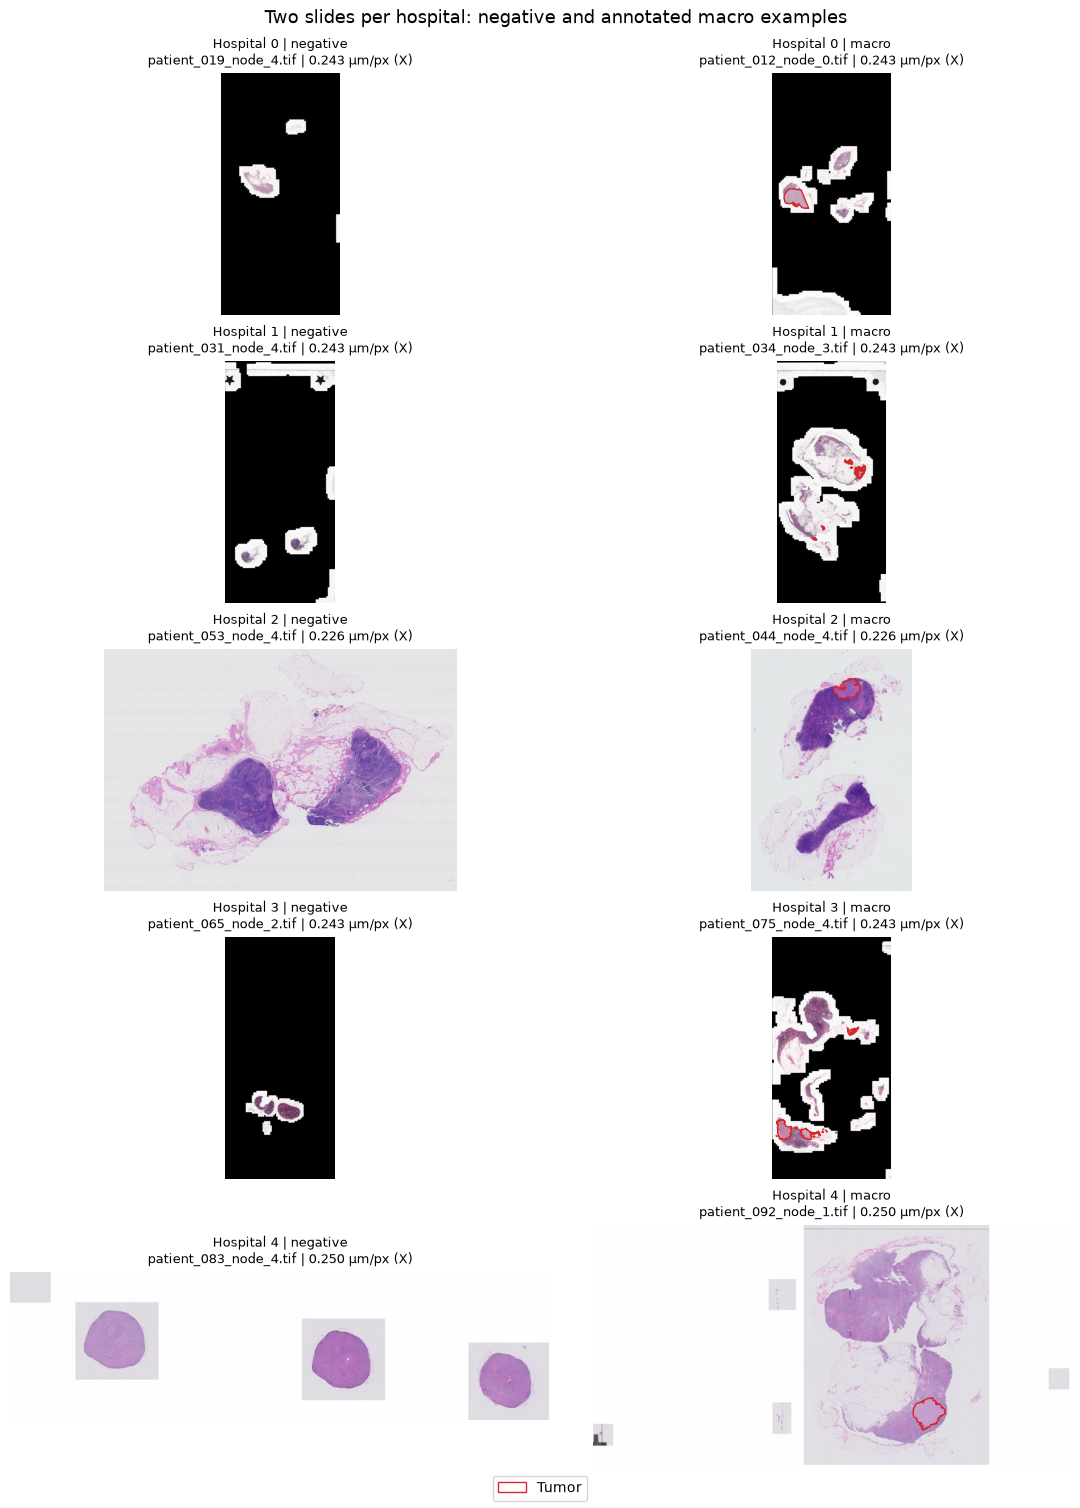

In [7]:
fig, axes = plt.subplots(5, 2, figsize=(11, 15), layout="constrained")
colors = {"Tumor": "#D62728", "Exclusion": "#00A6B2"}
for info in metadata_rows:
    slide_id = info["slide_id"]
    column = 0 if info["label"] == "negative" else 1
    axis = axes[info["hospital"], column]
    width, height = info["width_px"], info["height_px"]
    axis.imshow(thumbnails[slide_id], extent=(0, width, height, 0), origin="upper")
    for polygon in annotations[slide_id]:
        axis.add_patch(Polygon(
            polygon["xy"], closed=True, fill=False,
            edgecolor=colors[polygon["group"]], linewidth=1,
            linestyle="--" if polygon["group"] == "Exclusion" else "-",
        ))
    pixel_size = "MPP not recorded" if info["mpp_x"] is None else f"{info['mpp_x']:.3f} µm/px (X)"
    axis.set(xlim=(0, width), ylim=(height, 0),
             title=f"Hospital {info['hospital']} | {info['label']}\n{slide_id} | {pixel_size}")
    axis.title.set_fontsize(9)
    axis.set_axis_off()

present_groups = sorted({p["group"] for polygons in annotations.values() for p in polygons})
fig.legend(handles=[Patch(facecolor="none", edgecolor=colors[group], label=group)
                    for group in present_groups], loc="outside lower center", ncol=2)
fig.suptitle("Two slides per hospital: negative and annotated macro examples", fontsize=13)
fig.savefig(OUT / "hospital_thumbnail_grid.png", dpi=150)
plt.show()


## 7. Compare the recorded pixel sizes

The summary gives the range recorded in the two selected files from each hospital. A narrow range here does not establish that every slide at that hospital has the same calibration.

The level-1 table makes the next tiling decision concrete: if the physical pixel sizes differ at that level, reading level 1 from every file will not give a common tile scale. Missing calibration would need to be resolved before using that file for tiles at a specified physical size.


In [8]:
hospital_summary = metadata.groupby("hospital").agg(
    slides_checked=("slide_id", "size"),
    mpp_x_min=("mpp_x", "min"), mpp_x_max=("mpp_x", "max"),
    mpp_y_min=("mpp_y", "min"), mpp_y_max=("mpp_y", "max"),
    min_levels=("level_count", "min"), max_levels=("level_count", "max"),
    missing_objective=("objective_magnification", lambda values: values.isna().sum()),
)
missing_mpp = metadata["mpp_x"].isna() | metadata["mpp_y"].isna()
hospital_summary["missing_mpp"] = missing_mpp.groupby(metadata["hospital"]).sum()
display(hospital_summary.round(6))



,slides_checked,mpp_x_min,mpp_x_max,mpp_y_min,mpp_y_max,min_levels,max_levels,missing_objective,missing_mpp
hospital,,,,,,,,,
0,2,0.243094,0.243094,0.243094,0.243094,9,9,2,0
1,2,0.243094,0.243094,0.243094,0.243094,9,9,2,0
2,2,0.226316,0.226316,0.226321,0.226321,8,8,2,0
3,2,0.243094,0.243094,0.243094,0.243094,9,9,2,0
4,2,0.250000,0.250000,0.250000,0.250000,10,10,2,0


In [9]:
display(level_table.loc[level_table["level"].eq(1),
                        ["hospital", "slide_id", "downsample", "approx_mpp_x", "approx_mpp_y"]]
        .round(6).fillna("not recorded"))

,hospital,slide_id,downsample,approx_mpp_x,approx_mpp_y
1,0,patient_019_node_4.tif,2.000010,0.486190,0.486190
10,0,patient_012_node_0.tif,2.000010,0.486190,0.486190
19,1,patient_031_node_4.tif,2.000005,0.486189,0.486189
28,1,patient_034_node_3.tif,2.000005,0.486189,0.486189
37,2,patient_053_node_4.tif,2.000000,0.452632,0.452642
45,2,patient_044_node_4.tif,2.000000,0.452632,0.452642
53,3,patient_065_node_2.tif,2.000005,0.486189,0.486189
62,3,patient_075_node_4.tif,2.000010,0.486190,0.486190
71,4,patient_083_node_4.tif,2.000000,0.500000,0.500000
81,4,patient_092_node_1.tif,2.000000,0.500000,0.500000


## 8. Save the inspection results

The CSV files retain the complete metadata, resolution levels, and annotation counts. The JSON summary also records the software versions, source checksums, and the hash of the selection manifest.

All generated files stay in `data/derived/camelyon17/hospital_comparison/`. The manifest and notebook are small enough to keep in Git; the TIFFs stay in the ignored data directory.


In [10]:
metadata.to_csv(OUT / "slide_metadata.csv", index=False)
level_table.to_csv(OUT / "resolution_levels.csv", index=False)
annotation_table.to_csv(OUT / "annotation_counts.csv", index=False)
hospital_summary.to_csv(OUT / "hospital_summary.csv")
summary = {
    "inspected_at_utc": datetime.now(timezone.utc).isoformat(),
    "manifest": INSPECTION_MANIFEST.relative_to(ROOT).as_posix(),
    "manifest_sha256": manifest_sha256,
    "metadata_snapshot_utc": samples[0]["metadata_retrieved_at_utc"],
    "selection": "Smallest negative and smallest XML-annotated macro slide per hospital; filename breaks ties.",
    "total_image_bytes": sum(sample["files"]["image"]["bytes"] for sample in samples),
    "slide_metadata": metadata_rows,
    "annotation_counts": annotation_rows,
    "files": [
        {**details, "path": details["path"].relative_to(ROOT).as_posix(), "md5_verified": True}
        for sample in samples for details in sample["files"].values()
    ],
    "software": {
        "python": platform.python_version(),
        "openslide-python": version("openslide-python"),
        "openslide-library": openslide.__library_version__,
        **{package: version(package) for package in ("pillow", "numpy", "pandas", "matplotlib")},
    },
}
(OUT / "inspection_summary.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
print("Saved outputs under:", OUT.relative_to(ROOT))


Saved outputs under: data/derived/camelyon17/hospital_comparison


## Notes 

All ten slides opened on the Mac. The five XML files contain 99 tumor polygons, and every coordinate passed the image-bounds check. The larger outlines sit over tissue in the thumbnail grid. Small outlines need closer views before we use them to check tiles.

The recorded pixel sizes differ across this sample. Values below are rounded to six decimal places.

| Selected hospitals | Full-resolution µm/px (X / Y) | Resolution levels |
| --- | --- | --- |
| 0, 1, and 3 | 0.243094 / 0.243094 | 9 |
| 2 | 0.226316 / 0.226321 | 8 |
| 4 | 0.250000 / 0.250000 | 10 |

Every file records physical pixel sizes. None records objective magnification or an embedded color profile, so the thumbnails use the stored RGB values without profile conversion.

The selected images from hospitals 0, 1, and 3 have large black areas around the tissue. Hospitals 2 and 4 have pale backgrounds in these examples. A tissue mask must exclude both types of background. Two slides per hospital cannot tell us how common these appearances are.

## What I'll use for tiling

At level 1, a 256-pixel-wide crop would cover about 115.9 micrometers in the hospital 2 examples and 128 micrometers in hospital 4. I'll start the pilot at 0.5 micrometers per pixel, which is close to level 1 in all ten files, and resample using each file's recorded X and Y pixel sizes. At that target scale, a 256-pixel-wide tile would cover 128 micrometers.

The next step is a tissue mask and a small tile grid on this same set. I'll check the mask over both black and pale backgrounds, then compare tile positions with the thumbnails and tumor outlines.

## Sources

- [CAMELYON on AWS Open Data](https://registry.opendata.aws/camelyon/): source bucket and access information.
- The saved CAMELYON17 labels, file listing, README, and published MD5 checksums used in notebook 01.
- [CAMELYON17 challenge paper](https://geertlitjens.nl/publication/band-18/band-18.pdf): dataset construction and annotation coordinates.
- [OpenSlide Python documentation](https://openslide.org/api/python/): image levels, physical pixel-size properties, thumbnails, and color profiles.
